# 서브에이전트 위임

**이 노트북에서 할 일**

1. 규정 도구를 서브에이전트 명세에만 주어, 바깥 에이전트가 `task`로만 규정에 닿게 조립합니다.
2. 모델 없이 `task`를 손으로 불러, 서브에이전트가 무엇을 받고 무엇을 내놓는지 봅니다.
3. 실제 모델로 한 번 맡겨 보고, 서브에이전트의 요청까지 세어 Ch 26 셈과 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 5절에서 바깥 에이전트를 한 번 실행합니다.
노트북 밖에서 같은 질문을 다섯 번 보냈을 때, 요청은 다섯 번 모두 5번이었습니다.
바깥 에이전트 2번과 서브에이전트 3번을 더한 수입니다.

호출 한도는 바깥 10, 규정 확인 서브에이전트 4, general-purpose 2로 세 곳에 줍니다.
요금표로 어림한 예상 비용은 서브에이전트 요청까지 더해도 0.01달러 아래이고, 청구 금액이 아닙니다.
파일은 상태 칸 `files`에만 두고, 디스크에는 쓰지 않습니다.
모델의 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

앞에서 배운 함수 넷은 도구 파일 `harness_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 deepagents 0.7.0, langchain 1.4.0, langgraph 1.2.11입니다.
나머지 둘은 `langchain-openai` 1.6.0과 `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2·3절을 읽습니다.
모델 없이 위임의 조립과 서브에이전트가 받는 것을 보는 자리입니다.
4~6절은 실제 모델로 한 번 실행하는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위에 나란한 두 칸이 있습니다. 왼쪽 칸 rule-checker 명세에는 초록 상자 도구 lookup_rule과 초록 상자 자기 호출 한도 4 기록 훅이, 오른쪽 칸 general-purpose 명세에는 초록 상자 도구를 적지 않음 바깥 도구를 물려받음과 초록 상자 자기 호출 한도 2 기록 훅이 있습니다. 두 칸에서 파란 상자 create_deep_agent 인자 tools 없음 명세 둘로 화살표가 가고, 거기서 노란 상자 둘로 갈라집니다. 하나는 바깥 에이전트 도구 아홉 lookup_rule이 있는가 False, 다른 하나는 task 설명 글 두 이름 줄 True 기본 general-purpose 설명 False인 그림](attachment:06-1-맡겨야만-닿는-조립.png)

위에서 아래로 읽습니다.
맨 위 두 칸은 우리가 적은 명세이고, 서로 다른 서브에이전트라 나란히 두었습니다.
파란 상자는 우리가 부른 함수이고, 노란 상자 둘은 노트북 2·4절 출력입니다.
규정 도구는 rule-checker 명세에만 있어, 바깥 에이전트는 task로 맡겨야만 규정에 닿습니다.
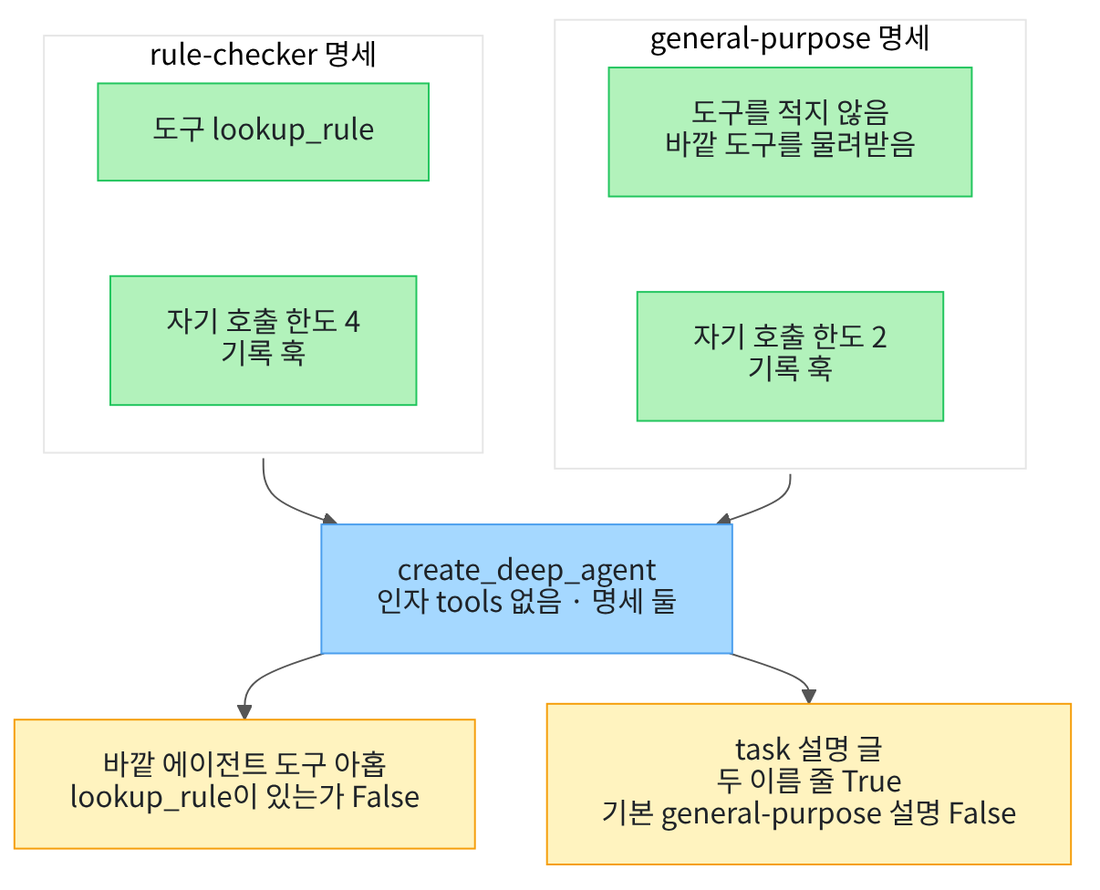

## 1. 준비

이 절에서는 Deep Agent가 일을 서브에이전트에게 맡기는 모양을 봅니다.
01절에서 본 것처럼, 바깥 에이전트는 도구 `task`로 서브에이전트를 부릅니다.
이번에는 규정 도구를 서브에이전트에게만 주어, 맡기지 않으면 규정에 닿지 못하게 조립합니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
deepagents: 0.7.0
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langgraph: 1.2.11`이 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판입니다.
패키지 langgraph는 3절에서 04절의 작은 그래프를 다시 만들려고 설치 목록에 넣었습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
훅 데코레이터 `before_agent`는 Ch 22 01절에서 배웠고, 이 챕터에서는 이 절에서 처음 씁니다.
마지막 가져오기 줄은 앞에서 배운 함수 넷을 도구 파일 `harness_tools.py`에서 가져옵니다.

In [2]:
# Deep Agents(01절)·상태 형식(04절)·미들웨어와 훅(Ch 22)·모델·메시지·도구·그래프 이름을 가져옵니다
from deepagents import create_deep_agent
from deepagents.middleware.filesystem import FilesystemState
from langchain.agents.middleware import ModelCallLimitMiddleware, before_agent, wrap_model_call
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, HumanMessage
from langchain.tools import tool
from langgraph.graph import END, START, StateGraph
# 앞 챕터와 01절에서 배운 함수 넷은 도구 파일에서 가져옵니다
from harness_tools import estimate_cost, show_messages, sum_usage, tool_names

print("도구 파일에서 가져온 함수:", "estimate_cost, show_messages, sum_usage, tool_names")

도구 파일에서 가져온 함수: estimate_cost, show_messages, sum_usage, tool_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, show_messages, sum_usage, tool_names`가 보입니다.
네 함수의 뜻은 02절 1절에 적었습니다.
앞에서 배운 함수는 `harness_tools.py`에 모아 두었고, 파일을 열면 코드를 볼 수 있습니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절 실행 셀에서만 나갑니다.

2·3절은 이 객체로 Deep Agent를 만들기만 하고, 모델을 부르지 않습니다.
이 절은 파일을 디스크에 쓰지 않고, 상태 칸 `files`만 씁니다.

## 2. 규정 도구를 서브에이전트에게만 주기

맡길 일은 02절처럼 자료실 규정을 찾는 일입니다.
다음 셀은 02절 2절의 규정 글 셀과 같은 글입니다.

In [5]:
# 도구가 찾을 교재용 규정 글 넷을 주제어마다 정합니다(실제 도서관 규정이 아님)
library_rules = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "연장": "반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
}
print("규정 주제어:", list(library_rules))

규정 주제어: ['대출', '연장', '연체', '운영']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '연장', '연체', '운영']`이 보입니다.
02절과 같은 교재용 규정이고, 실제 도서관 규정이 아닙니다.

다음 셀도 02절의 도구 셀과 같은 글입니다.
맨 위 `@tool` 줄이 아래 함수를 도구로 등록하는 것도 02절과 같습니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_rule(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 연장, 연체, 운영 가운데 하나를 넣습니다."""
    # 없는 주제어면 오류 대신 정해 둔 안내 글을 내놓습니다
    if topic in library_rules:
        return library_rules[topic]
    return "그런 주제어의 규정은 없습니다. 대출, 연장, 연체, 운영 가운데 하나를 넣어 주세요."

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 `lookup_rule`은 주제어 하나로 규정 글 하나를 찾습니다.
이 절에서는 이 도구를 서브에이전트 명세에만 넣고, 바깥 에이전트에는 주지 않습니다.

5절에서는 서브에이전트의 요청까지 세어 봅니다.
그래서 명세를 만들기 전에, 요청마다 모델이 받은 도구 이름을 적는 기록 훅을 먼저 만듭니다.
다음 셀은 02절 5절의 기록 훅 셀과 같은 글입니다.

In [7]:
# 모델 요청이 나갈 때마다, 그 요청에 실린 도구 이름을 기록 목록에 붙이는 훅입니다(Ch 22 02절 기록 훅 모양)
@wrap_model_call
def record_tool_names(request, handler):
    names = []
    for item in request.tools:
        names.append(item.name)
    seen_tool_lists.append(names)
    # 기록만 하고, 요청은 그대로 모델에게 보냅니다
    return handler(request)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 훅은 요청마다 모델이 받은 도구 이름 목록을 `seen_tool_lists`에 붙입니다.
이 훅을 바깥 에이전트와 서브에이전트에 모두 넣으면, 받은 도구로 누구의 요청인지 가를 수 있습니다.

다음 셀은 규정 확인을 맡을 서브에이전트 명세입니다.
01절에서 명세는 서브에이전트의 이름·설명·시스템 메시지 글·미들웨어를 적은 딕셔너리라고 했습니다.
이번에는 키 `tools`도 적어, 이 서브에이전트만 쓸 도구를 줍니다.
키마다 한 줄로 적었습니다.

In [8]:
# 규정 확인을 맡을 서브에이전트 명세를 키마다 한 줄로 적습니다(자기 호출 한도 4와 기록 훅을 넣음)
checker_limit = ModelCallLimitMiddleware(run_limit=4, exit_behavior="end")
rule_checker = {
    "name": "rule-checker",
    "description": "교육센터 자료실 규정을 찾아 확인하는 담당입니다. 규정 도구 lookup_rule은 이 담당만 가졌습니다.",
    "system_prompt": "맡은 일에 맞는 규정을 lookup_rule로 찾으세요. 찾은 규정 글을 write_file로 /notes/rule-check.md에 적으세요. 그다음 찾은 내용을 두 문장의 한국어로 보고하세요.",
    "tools": [lookup_rule],
    "middleware": [checker_limit, record_tool_names],
}
print("명세의 키:", list(rule_checker))
print("자기 호출 한도:", checker_limit.run_limit)

명세의 키: ['name', 'description', 'system_prompt', 'tools', 'middleware']
자기 호출 한도: 4


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'tools', 'middleware']`가 보입니다.
키 `name`은 `task`로 부를 이름이고, `description`은 바깥 모델이 읽고 고를 설명입니다.
키 `system_prompt`는 서브에이전트의 시스템 메시지 글이고, 무엇을 남기면 끝나는지 적었습니다.
키 `tools`의 도구는 이 서브에이전트만 받고, `middleware`에는 호출 한도와 기록 훅을 넣었습니다.
출력 줄 `자기 호출 한도: 4`는 찾기·적기·보고 세 요청에 하나를 더한 값입니다.

설치판 `graph.py` 728행에서, 키 `tools`가 없으면 바깥 에이전트의 도구를 물려받습니다.
적으면 그 목록이 물려받을 도구를 대신합니다.

다음 셀은 이 명세 하나만 넘겨 바깥 에이전트를 만듭니다.
인자 `tools=`는 넘기지 않아, 바깥 에이전트에는 규정 도구가 없습니다.

In [9]:
# 조회 도구 없이, 규정 확인 명세 하나만 넘겨 바깥 에이전트를 만듭니다(요청은 보내지 않음)
plain_parent = create_deep_agent(model=model, subagents=[rule_checker])
plain_tools = tool_names(plain_parent)
print("바깥 에이전트의 도구 수:", len(plain_tools))
print("바깥 에이전트에 lookup_rule이 있는가:", "lookup_rule" in plain_tools)

바깥 에이전트의 도구 수: 9
바깥 에이전트에 lookup_rule이 있는가: False


**결과 읽기** — 출력 줄 `바깥 에이전트의 도구 수: 9`와 `바깥 에이전트에 lookup_rule이 있는가: False`가 보입니다.
01절에서 본 기본 도구 아홉 그대로이고, 규정 도구는 없습니다.
바깥 에이전트가 규정을 보려면 `task`로 맡기는 길밖에 없습니다.
맡길지 말지가 모델의 선택만이 아니라, 조립으로도 정해진 셈입니다.

도구 `task`의 설명 글에는 맡길 수 있는 서브에이전트가 「- 이름: 설명」 줄로 적힙니다.
설치판 `middleware/subagents.py` 464~468행이 그 글을 만듭니다.
다음 셀은 이름 목록을 받아, 이름마다 그 줄이 있는지 출력하는 함수입니다.
기본 general-purpose의 설명 글이 남았는지도 함께 출력합니다.

In [10]:
# task 설명 글에 서브에이전트 이름마다 「- 이름:」 줄이 있는지와, 기본 general-purpose 설명이 남았는지 출력합니다
def show_task_names(agent, names):
    task_text = agent.nodes["tools"].bound.tools_by_name["task"].description
    for name in names:
        print(name, "줄이 있는가:", "- " + name + ":" in task_text)
    print("기본 general-purpose 설명이 남았는가:", "General-purpose agent" in task_text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기본 general-purpose의 설명 글은 「General-purpose agent」로 시작해서, 그 글이 있는지로 봅니다.

다음 셀은 명세 하나만 넘긴 바깥 에이전트로 이 함수를 부릅니다.
실행 전에 예상해 봅니다.
넘긴 명세는 rule-checker 하나이니, 이름 줄도 하나일까요?

In [11]:
# 명세 하나만 넘긴 바깥 에이전트의 task 설명 글을 봅니다
subagent_names = ["general-purpose", "rule-checker"]
show_task_names(plain_parent, subagent_names)

general-purpose 줄이 있는가: True
rule-checker 줄이 있는가: True
기본 general-purpose 설명이 남았는가: True


**결과 읽기** — 출력 줄 `general-purpose 줄이 있는가: True`와 `rule-checker 줄이 있는가: True`가 보입니다.
출력 줄 `기본 general-purpose 설명이 남았는가: True`도 보입니다.
명세는 rule-checker 하나만 넘겼는데, 기본 general-purpose 서브에이전트도 함께 붙었습니다.
01절에서 본 것처럼, 이 기본 서브에이전트에는 호출 한도가 없습니다.

그래서 01절처럼 같은 이름 general-purpose 명세도 함께 넘깁니다.
다음 셀은 02절 명세 글에 기록 훅 하나만 더한 명세입니다.
기본 서브에이전트에는 바깥 미들웨어가 옮겨 가지 않아, 기록 훅도 명세에 따로 넣어야 요청이 적힙니다.

In [12]:
# 02절 general-purpose 명세에 기록 훅 하나만 더해, 기본 자리를 바꿀 명세를 만듭니다(자기 호출 한도 2)
helper_limit = ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit, record_tool_names],
}
print("명세의 키:", list(helper_spec))
print("자기 호출 한도:", helper_limit.run_limit)

명세의 키: ['name', 'description', 'system_prompt', 'middleware']
자기 호출 한도: 2


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`와 `자기 호출 한도: 2`가 보입니다.
키 `tools`가 없어, 이 서브에이전트는 바깥 에이전트의 도구를 물려받습니다.
바깥 에이전트에 넘긴 도구가 없으니, 설치판 소스대로라면 받는 도구는 파일 도구뿐입니다.
이 명세를 함께 넘긴 조립은 4절에서 봅니다.

## 3. 모델 없이 task를 불러 보기

서브에이전트가 무엇을 받고 시작하는지 모델 없이 보려고, 04절의 작은 그래프 함수를 다시 씁니다.
다음 셀은 04절 3절 셀과 같은 글입니다.

In [13]:
# Deep Agent 하나를 받아, 그 도구 실행 노드 하나만 든 작은 그래프를 만들어 내놓습니다(상태 형식은 files 칸이 있는 FilesystemState)
def tools_only_graph(agent):
    builder = StateGraph(FilesystemState)
    builder.add_node("tools", agent.nodes["tools"].bound)
    builder.add_edge(START, "tools")
    builder.add_edge("tools", END)
    return builder.compile()

**결과 읽기** — 정의 셀이라 출력이 없습니다.
작은 그래프의 상태 형식에는 칸 `files`가 있어, 입력에 파일을 함께 넣을 수 있습니다.

다음 셀은 서브에이전트가 시작할 때 받은 것을 적는 훅입니다.
맨 위 `@before_agent` 줄은 아래 함수를, 에이전트 실행이 시작될 때 한 번 도는 훅으로 등록합니다.
Ch 22 01절에서 본 노드형 훅이고, 인자 `state`로 그때의 상태를 받습니다.
기록 한 줄은 한국어 키 딕셔너리로 적습니다.

In [14]:
# 서브에이전트 실행이 시작될 때 한 번, 받은 메시지와 파일 위치를 기록 목록에 붙이는 훅입니다(Ch 22 01절 before_agent)
@before_agent
def record_inputs(state, runtime):
    first_message = state["messages"][0]
    record = {
        "메시지 수": len(state["messages"]),
        "첫 메시지 종류": type(first_message).__name__,
        "첫 메시지 글": first_message.text,
        "파일 위치": list(state["files"]),
    }
    seen_inputs.append(record)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
받은 메시지 수, 첫 메시지의 종류와 글, 상태 칸 `files`의 파일 위치를 적습니다.

모델 없이 보려면, 서브에이전트가 모델을 부르기 전에 멈춰야 합니다.
01절 6절처럼 호출 한도 0을 쓰면, 모델 요청 없이 한도 글만 남기고 끝납니다.
다음 셀은 규정 확인 명세를 복사해, 미들웨어만 이 훅과 한도 0으로 바꿉니다.
메서드 `copy`는 Ch 18 05절처럼 딕셔너리를 한 벌 더 만듭니다.

In [15]:
# 규정 확인 명세를 복사해, 미들웨어만 시작 기록 훅과 호출 한도 0으로 바꿉니다(모델을 부르기 전에 멈추게)
zero_limit = ModelCallLimitMiddleware(run_limit=0, exit_behavior="end")
zero_checker = rule_checker.copy()
zero_checker["middleware"] = [record_inputs, zero_limit]
print("같은 이름인가:", zero_checker["name"] == rule_checker["name"])
print("원래 명세의 미들웨어 수:", len(rule_checker["middleware"]))

같은 이름인가: True
원래 명세의 미들웨어 수: 2


**결과 읽기** — 출력 줄 `같은 이름인가: True`와 `원래 명세의 미들웨어 수: 2`가 보입니다.
복사본의 키를 바꿔도 원래 명세는 그대로입니다.
시작 기록 훅은 모델 앞에서 한도를 따지기 전, 실행 첫머리에 한 번 돕니다.

다음 셀은 복사본과 general-purpose 명세로 바깥 에이전트를 만듭니다.
그리고 도구 실행 노드만 든 작은 그래프를 만듭니다.

In [16]:
# 복사본과 general-purpose 명세로 바깥 에이전트를 만들고, 도구 실행 노드만 든 작은 그래프를 만듭니다(요청은 보내지 않음)
zero_parent = create_deep_agent(model=model, subagents=[zero_checker, helper_spec])
zero_graph = tools_only_graph(zero_parent)
zero_nodes = zero_graph.get_graph().nodes
print("작은 그래프의 노드:", list(zero_nodes))

작은 그래프의 노드: ['__start__', 'tools', '__end__']


**결과 읽기** — 출력 줄 `작은 그래프의 노드: ['__start__', 'tools', '__end__']`가 보입니다.
도구 실행 노드에는 도구 `task`도 들어 있어, 손으로 만든 `task` 요청을 넣을 수 있습니다.

먼저 04절 3절처럼 손 요청으로 메모 파일 하나를 상태 칸 `files`에 적습니다.
바깥 상태에 있는 파일이 서브에이전트에게도 보이는지 보려는 것입니다.

In [17]:
# 모델 없이, 메모 파일 하나를 쓰는 write_file 요청을 손으로 만들어 작은 그래프에 넣습니다(04절 3절 모양)
memo_args = {"file_path": "/notes/question.md", "content": "문의: 빌린 책의 반납 날짜를 늘리는 방법"}
memo_call = {"name": "write_file", "args": memo_args, "id": "hand_write_1", "type": "tool_call"}
memo_request = AIMessage(content="", tool_calls=[memo_call])
memo_result = zero_graph.invoke({"messages": [memo_request]})
print("도구 메시지:", memo_result["messages"][-1].content)
print("상태 칸 files의 파일 위치:", list(memo_result["files"]))

도구 메시지: Updated file /notes/question.md
상태 칸 files의 파일 위치: ['/notes/question.md']


**결과 읽기** — 출력 줄 `도구 메시지: Updated file /notes/question.md`가 보입니다.
출력 줄 `상태 칸 files의 파일 위치: ['/notes/question.md']`에서, 메모 파일이 상태 칸에 생겼습니다.

다음 셀은 rule-checker에게 맡기는 `task` 요청을 손으로 만듭니다.
인자는 01절에서 본 둘로, 넘길 글 `description`과 서브에이전트 이름 `subagent_type`입니다.
앞 셀 결과의 `files`를 입력에 함께 넣어, 바깥 상태에 메모 파일이 있는 채로 부릅니다.
실행 전에 예상해 봅니다.
서브에이전트는 넘긴 글 한 줄로 시작하고, 모델을 부르기 전에 멈출 것입니다.

In [18]:
# 모델 없이, rule-checker에게 맡기는 task 요청을 손으로 만들어, 메모 파일이 든 상태와 함께 넣습니다
task_args = {"description": "대출 연장 규정을 확인해 주세요.", "subagent_type": "rule-checker"}
task_call = {"name": "task", "args": task_args, "id": "hand_task_1", "type": "tool_call"}
task_request = AIMessage(content="", tool_calls=[task_call])
seen_inputs = []
zero_input = {"messages": [task_request], "files": memo_result["files"]}
zero_result = zero_graph.invoke(zero_input)
print("서브에이전트가 시작할 때 받은 것:", seen_inputs)

서브에이전트가 시작할 때 받은 것: [{'메시지 수': 1, '첫 메시지 종류': 'HumanMessage', '첫 메시지 글': '대출 연장 규정을 확인해 주세요.', '파일 위치': ['/notes/question.md']}]


**결과 읽기** — 라벨 `서브에이전트가 시작할 때 받은 것:` 뒤에 기록 한 줄이 보입니다.
메시지 수는 1이고, 첫 메시지는 `HumanMessage`이며 글은 넘긴 글 그대로입니다.
파일 위치에는 `/notes/question.md`가 있습니다.
서브에이전트는 바깥 메시지 목록 없이, 넘긴 글 한 줄과 바깥 상태 칸 `files`로 시작했습니다.
Ch 26 01절의 안쪽 목록처럼 새 목록으로 시작하지만, 파일은 함께 봅니다.

설치판 `middleware/subagents.py` 537~539행에서, 바깥 상태의 칸 가운데 `messages`·`todos` 등을 빼고 넘깁니다.
다음 셀은 바깥으로 온 도구 메시지와, 실행 뒤 상태 칸 `files`를 봅니다.

In [19]:
# 바깥으로 온 도구 메시지와, 실행 뒤 상태 칸 files를 봅니다
zero_message = zero_result["messages"][-1]
print("도구 메시지 종류:", type(zero_message).__name__, "| 도구 이름:", zero_message.name)
print("도구 메시지 내용:", zero_message.content)
print("결과 메시지 수:", len(zero_result["messages"]))
print("상태 칸 files의 파일 위치:", list(zero_result["files"]))

도구 메시지 종류: ToolMessage | 도구 이름: task
도구 메시지 내용: Model call limits exceeded: run limit (0/0)
결과 메시지 수: 2
상태 칸 files의 파일 위치: ['/notes/question.md']


**결과 읽기** — 출력 줄 `도구 메시지 내용: Model call limits exceeded: run limit (0/0)`이 보입니다.
서브에이전트는 모델을 한 번도 부르지 않고 한도 글만 남긴 채 끝났습니다.
도구 `task`는 서브에이전트의 마지막 글 하나를 도구 메시지에 담아 바깥 목록에 넣습니다.
출력 줄 `결과 메시지 수: 2`는 손 요청 하나와 그 도구 메시지 하나입니다.
메모 파일은 실행 뒤에도 상태 칸에 그대로 있고, 이 셀까지 모델 요청은 0번입니다.

서브에이전트가 새로 쓴 파일이 바깥 상태 칸에 더해지는지는, 모델이 있어야 보입니다.
설치판 `middleware/subagents.py` 474~512행은 서브에이전트 결과의 칸을 바깥 상태의 갱신으로 넘깁니다.
5절 실행에서 그 모양을 봅니다.

## 4. 실제 모델을 부를 준비

5절에서는 이 조립에 실제 모델을 붙여 한 번 맡겨 봅니다.
다음 셀은 03절 셀과 같은 글의 바깥 호출 한도입니다.

In [20]:
# 바깥 에이전트의 모델 요청을 열 번까지로 막는 호출 한도를 만듭니다(02절 셀과 한도만 다름)
outer_limit = ModelCallLimitMiddleware(run_limit=10, exit_behavior="end")
print("바깥 호출 한도:", outer_limit.run_limit)

바깥 호출 한도: 10


**결과 읽기** — 출력 줄 `바깥 호출 한도: 10`이 보입니다.
주석의 「02절 셀과 한도만 다름」은 이 셀을 처음 쓴 03절에서 적은 말입니다.

이제 호출 한도가 세 곳에 있습니다.
바깥 10, rule-checker 4, general-purpose 2입니다.
도구 `task`는 부를 때마다 서브에이전트를 새로 실행해서, 명세의 한도도 한 번 부를 때마다 새로 셉니다.
그래서 한 번 실행의 요청 수는 10에 두 값을 더한 수를 넘지 않습니다.
두 값은 rule-checker를 부른 횟수 × 4와 general-purpose를 부른 횟수 × 2입니다.

다만 한 응답에 `task` 요청을 몇 개 담을지는 막지 못해, 그 수만큼 상한이 커집니다.
다음 셀은 바깥 에이전트를 만듭니다.
인자 `tools=`는 이번에도 넘기지 않고, 두 명세를 함께 넘깁니다.
우리 시스템 메시지 글에는 규정을 직접 찾지 말고 rule-checker에게 맡기라고 적었습니다.

In [21]:
# 조회 도구 없이, 호출 한도·기록 훅·두 명세·우리 시스템 메시지 글을 넘겨 바깥 에이전트를 만듭니다(요청은 아직 보내지 않음)
parent_text = "자료실 규정은 직접 찾지 말고, task 도구로 rule-checker에게 맡기세요. 받은 보고를 바탕으로 두 문장의 한국어로 답하세요."
run_parent = create_deep_agent(
    model=model,
    system_prompt=parent_text,
    middleware=[outer_limit, record_tool_names],
    subagents=[rule_checker, helper_spec],
)
print("바깥 에이전트에 lookup_rule이 있는가:", "lookup_rule" in tool_names(run_parent))
show_task_names(run_parent, subagent_names)

바깥 에이전트에 lookup_rule이 있는가: False
general-purpose 줄이 있는가: True
rule-checker 줄이 있는가: True
기본 general-purpose 설명이 남았는가: False


**결과 읽기** — 출력 줄 `바깥 에이전트에 lookup_rule이 있는가: False`가 보입니다.
출력 줄 `기본 general-purpose 설명이 남았는가: False`에서, 같은 이름 명세가 기본 자리를 바꿨습니다.
두 이름 줄은 모두 `True`라, 이 바깥 에이전트가 맡길 수 있는 곳은 우리 명세 둘뿐입니다.
두 명세 모두 호출 한도가 있고, 기록 훅은 바깥과 두 명세에 모두 들어 있습니다.

## 5. 실제 모델로 맡겨 보기

질문은 02절과 같은 글입니다.
실행 전에 예상해 봅니다.
바깥 에이전트는 `task`로 rule-checker에게 맡길 것입니다.
그러면 rule-checker는 규정을 찾아 파일에 적은 뒤 보고할 것입니다.

In [22]:
# 기록 목록을 새로 만들고, 02절과 같은 질문 한 줄로 한 번 실행합니다
seen_tool_lists = []
question = "교육센터 자료실에서 빌린 책의 반납 날짜를 늘리려면 어떻게 하나요? 두 문장으로 답해 주세요."
first_input = {"messages": [HumanMessage(content=question)]}
input_count = len(first_input["messages"])
run_result = run_parent.invoke(first_input)
run_messages = run_result["messages"]
print("결과 메시지 수:", len(run_messages))

결과 메시지 수: 4


**결과 읽기** — 라벨 `결과 메시지 수:` 뒤에 바깥 목록의 메시지 수가 보입니다.
넣은 질문 하나 뒤에, 바깥 모델의 응답과 도구 메시지가 더해졌습니다.

이번 실행에서는 `결과 메시지 수: 4`였습니다.
질문 하나, `task` 요청 응답, 도구 메시지, 마지막 답입니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 모두 넷이었습니다.

다음 셀은 Ch 19 06절 함수 `show_messages`로 바깥 목록을 차례로 봅니다.

In [23]:
# 바깥 목록(결과 메시지)을 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("바깥 목록:")
show_messages(run_messages)

바깥 목록:
HumanMessage
AIMessage | 도구 호출 요청: ['task']
ToolMessage | 결과 상태: success | 내용: 반납 예정일이 지나기 전에 한 번에 한해 7일 연장이 가능합니다. 다만 해당 책에 예약자가 있으면 연장할 수 없으므로, 반납 전에 예약 여부를 먼저 확인해야 합니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래가 바깥 목록의 메시지 차례입니다.
`ToolMessage` 줄의 내용은 서브에이전트가 마지막에 쓴 보고 글입니다.
바깥 목록에는 서브에이전트의 응답도, 서브에이전트가 부른 도구의 메시지도 없습니다.
마지막 `AIMessage` 줄은 도구 요청이 없는 응답이고, 바깥 모델이 쓴 답입니다.

이번 실행에서 바깥 모델은 첫 응답에서 `task`를 한 번 요청했고, 도구 메시지를 받은 뒤 답했습니다.
노트북 밖 다섯 번과 새 커널 두 번에서 모두 이 차례였습니다.
보고 글은 서브에이전트가 쓴 글이라 실행마다 달라지고, 새 커널 두 번에서도 글이 달랐습니다.
바깥 모델이 `task`에 넘긴 글도 노트북 밖 다섯 번에서 모두 달랐습니다.

다음 셀은 이번 실행이 더한 응답에서 `task` 요청을 골라, 맡긴 서브에이전트 이름을 모읍니다.

In [24]:
# 이번 실행이 더한 응답에서 task 요청을 골라, 맡긴 서브에이전트 이름을 모읍니다
run_new = run_messages[input_count:]
asked_types = []
for message in run_new:
    if type(message).__name__ == "AIMessage":
        for call in message.tool_calls:
            if call["name"] == "task":
                asked_types.append(call["args"]["subagent_type"])
print("task로 맡긴 서브에이전트:", asked_types)

task로 맡긴 서브에이전트: ['rule-checker']


**결과 읽기** — 라벨 `task로 맡긴 서브에이전트:` 뒤에 이름 목록이 보입니다.
모델이 도구 `task`를 부르며 인자 `subagent_type`에 적은 이름입니다.

이번 실행에서는 `task로 맡긴 서브에이전트: ['rule-checker']`였습니다.
노트북 밖 다섯 번과 새 커널 두 번에서 모두 rule-checker에게 한 번 맡겼습니다.
general-purpose에게 맡긴 적은 없었습니다.
어디에 몇 번 맡길지는 모델이 정하는 값이라, 실행마다 달라질 수 있습니다.

다음 셀은 바깥 목록의 도구 메시지 이름을 모읍니다.
서브에이전트가 부른 도구의 메시지가 바깥 목록에 있는지 봅니다.

In [25]:
# 바깥 목록의 도구 메시지 이름을 모아, 서브에이전트가 부른 도구의 메시지가 있는지 봅니다
outer_tool_names = []
for message in run_new:
    if type(message).__name__ == "ToolMessage":
        outer_tool_names.append(message.name)
print("바깥 목록의 도구 메시지 이름:", outer_tool_names)
print("lookup_rule 도구 메시지가 있는가:", "lookup_rule" in outer_tool_names)
print("write_file 도구 메시지가 있는가:", "write_file" in outer_tool_names)

바깥 목록의 도구 메시지 이름: ['task']
lookup_rule 도구 메시지가 있는가: False
write_file 도구 메시지가 있는가: False


**결과 읽기** — 출력 줄 `lookup_rule 도구 메시지가 있는가: False`가 보입니다.
바깥 에이전트에는 규정 도구가 없어, 이 값은 조립으로 정해집니다.
서브에이전트가 부른 도구의 결과는 서브에이전트 안에만 남고, 바깥 목록에는 오지 않습니다.

이번 실행에서는 `바깥 목록의 도구 메시지 이름: ['task']`였고, `write_file` 도구 메시지도 없었습니다.
바깥 모델이 부른 도구는 `task` 하나였다는 뜻입니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.

다음 셀은 실행 뒤 상태 칸 `files`를 봅니다.

In [26]:
# 실행 뒤 상태 칸 files를 보고, 보고 파일이 있으면 그 글을 봅니다
note_path = "/notes/rule-check.md"
print("상태 칸 files의 파일 위치:", list(run_result["files"]))
if note_path in run_result["files"]:
    print("보고 파일의 글:")
    print(run_result["files"][note_path]["content"])

상태 칸 files의 파일 위치: ['/notes/rule-check.md']
보고 파일의 글:
반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다.


**결과 읽기** — 라벨 `상태 칸 files의 파일 위치:` 뒤에 파일 위치 목록이 보입니다.
보고 파일이 있으면, 라벨 `보고 파일의 글:` 아래에 그 글이 보입니다.

이번 실행에서는 `상태 칸 files의 파일 위치: ['/notes/rule-check.md']`였습니다.
바깥 목록에는 `write_file` 도구 메시지가 없었으니, 이 파일은 서브에이전트가 적은 것입니다.
서브에이전트가 쓴 파일이 바깥 결과의 상태 칸에 더해졌습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 이 파일이 있었고, 글은 연장 규정 글과 같았습니다.
파일에 무엇을 적을지는 모델이 정하므로, 글은 실행마다 달라질 수 있습니다.

## 6. 요청 수 세기와 예상 비용

바깥 목록만 세면 서브에이전트의 요청이 빠집니다.
다음 셀은 기록 훅 목록을 받은 도구로 나눠 셉니다.
도구 `task`를 받은 요청은 바깥 요청이고, `lookup_rule`을 받은 요청은 rule-checker의 요청입니다.

In [27]:
# 기록 훅이 적은 요청을, task를 받은 요청(바깥)과 lookup_rule을 받은 요청(rule-checker)으로 나눠 셉니다
outer_count = 0
checker_count = 0
for names in seen_tool_lists:
    if "task" in names:
        outer_count = outer_count + 1
    if "lookup_rule" in names:
        checker_count = checker_count + 1
print("기록 훅이 센 요청 수:", len(seen_tool_lists))
print("task를 받은 요청(바깥):", outer_count)
print("lookup_rule을 받은 요청(rule-checker):", checker_count)

기록 훅이 센 요청 수: 5
task를 받은 요청(바깥): 2
lookup_rule을 받은 요청(rule-checker): 3


**결과 읽기** — 라벨 `기록 훅이 센 요청 수:` 뒤가 이번 실행의 모델 요청을 모두 센 수입니다.
서브에이전트에는 도구 `task`가 없어, 두 도구를 함께 받은 요청은 생기지 않습니다.
설치판 `graph.py` 666~674행에서 서브에이전트의 기본 미들웨어에는 서브에이전트 미들웨어가 없습니다.

이번 실행에서는 `기록 훅이 센 요청 수: 5`였습니다.
그 가운데 `task를 받은 요청(바깥): 2`, `lookup_rule을 받은 요청(rule-checker): 3`이었습니다.
기본 자리를 바꾼 general-purpose의 요청은 없어, 두 수를 더하면 합과 같습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같은 수였습니다.

다음 셀은 바깥 목록에서 센 요청 수를 기록 훅이 센 바깥 요청 수와 견줍니다.

In [28]:
# 바깥 목록에서 이번 실행이 더한 메시지만 Ch 19 05절 함수 sum_usage로 세고, 기록 훅이 센 바깥 요청 수와 견줍니다
run_usage = sum_usage(run_new)
print("바깥 목록으로 센 요청 수:", run_usage["requests"])
print("기록 훅이 센 바깥 요청 수:", outer_count)
print("입력 토큰:", run_usage["input_tokens"], "| 출력 토큰:", run_usage["output_tokens"])

바깥 목록으로 센 요청 수: 2
기록 훅이 센 바깥 요청 수: 2
입력 토큰: 3957 | 출력 토큰: 172


**결과 읽기** — 라벨 `바깥 목록으로 센 요청 수:`와 `기록 훅이 센 바깥 요청 수:` 뒤의 수가 같습니다.
바깥 목록의 응답은 모두 바깥 에이전트의 요청입니다.
입력·출력 토큰도 바깥 요청만의 합입니다.

이번 실행에서는 바깥 요청 2번, `입력 토큰: 3957 | 출력 토큰: 172`였습니다.
새 커널 두 번째는 입력 3965·출력 180으로, 토큰은 실행마다 조금씩 달랐습니다.
바깥 요청 수는 도구를 요청한 바깥 응답 하나에 1을 더한 값입니다.

다음 셀은 Ch 26 01절의 셈을 이번 실행에 대 봅니다.
그 셈은 바깥 요청 수에 서브에이전트를 부른 횟수 × 1을 더했습니다.

In [29]:
# Ch 26 01절 셈(바깥 요청 수 + 부른 횟수 × 1)을 이번 실행에 대 보고, 기록 훅이 센 요청 수와 견줍니다
ch26_inner_requests = 1
ch26_count = run_usage["requests"] + len(asked_types) * ch26_inner_requests
print("Ch 26 셈으로 센 요청 수:", ch26_count)
print("기록 훅이 센 요청 수:", len(seen_tool_lists))
print("두 수가 같은가:", ch26_count == len(seen_tool_lists))
print("바깥 요청 수 + rule-checker 요청 수:", outer_count + checker_count)

Ch 26 셈으로 센 요청 수: 3
기록 훅이 센 요청 수: 5
두 수가 같은가: False
바깥 요청 수 + rule-checker 요청 수: 5


**결과 읽기** — 라벨 `Ch 26 셈으로 센 요청 수:` 뒤와 `기록 훅이 센 요청 수:` 뒤를 견줍니다.
Ch 26 01절의 전문 에이전트는 도구가 없어, 한 번 부르면 모델 요청이 한 번이었습니다.
이 절의 서브에이전트는 도구를 가져, 한 번 부를 때 요청이 여러 번 나갈 수 있습니다.
셈은 바깥 요청 수에, 부른 횟수 × 그 실행 안 요청 수를 더하는 모양이 됩니다.

이번 실행에서는 `Ch 26 셈으로 센 요청 수: 3`, `기록 훅이 센 요청 수: 5`였습니다.
서브에이전트를 한 번 불렀지만, 그 안에서 요청이 세 번 나갔기 때문입니다.
노트북 밖 기록에서 rule-checker는 규정 도구, `write_file`, 보고의 차례로 응답했습니다.
그래서 셈은 바깥 2에 1 × 3을 더한 5이고, 흔들림 확인 다섯 번과 두 커널에서 같았습니다.

다음 셀은 02절과 같은 요금표로 예상 비용을 셉니다.
바깥 목록의 응답만으로 세므로, 라벨에 「바깥 요청의」를 붙였습니다.

In [30]:
# 2026-09-17 요금표(100만 토큰당 달러)로 바깥 요청의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost — 서브에이전트 요청은 빠짐)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
outer_cost = estimate_cost(run_usage, input_rate, cached_input_rate, output_rate)
rounded_cost = round(outer_cost, 6)
print("바깥 요청의 예상 비용(달러):", rounded_cost)

바깥 요청의 예상 비용(달러): 0.003742


**결과 읽기** — 라벨 `바깥 요청의 예상 비용(달러):` 뒤에 어림값이 보입니다.
바깥 목록의 응답만으로 셈해서, 서브에이전트 요청의 토큰은 들어 있지 않습니다.
이 노트북의 기록 훅은 도구 이름만 적어, 서브에이전트 요청의 토큰은 세지 않았습니다.
예상 비용은 청구 금액이 아닙니다.

이번 실행에서는 `바깥 요청의 예상 비용(달러): 0.003742`였습니다.
노트북 밖 다섯 번에서 서브에이전트 요청까지 센 값은 0.0083에서 0.0086달러 사이였습니다.
바깥 요청만의 값은 그 절반쯤이었습니다.
두 값 모두 입력 토큰을 모두 입력 요금으로 센 어림입니다.

## 정리

1. 규정 도구를 서브에이전트 명세에만 주면, 바깥 에이전트는 `task`로 맡겨야만 규정에 닿습니다.
2. 서브에이전트는 넘긴 글 한 줄과 바깥 상태 칸 `files`로 시작하고, 바깥 목록에는 마지막 보고 글 하나만 옵니다.
3. 바깥 목록만 세면 서브에이전트 요청이 빠지고, 도구를 가진 서브에이전트는 한 번에 요청을 여러 번 보낼 수 있습니다.

07절에서는 교재용 자료를 상태 칸 `files`에 넣고, 모델이 파일 도구로 찾아 쓴 조사를 봅니다.
모델이 든 출처 파일이 실제로 있는지는 코드로 확인합니다.